# Bedroom Humidity Forecasting


***

#### Notebook Overview


#### Data Overview

***
#### Key Findings

#### Next Steps

## Imports

In [1]:
# preprocessing
from utils import DataCleanPipleLine

# funcs
from utils.useful_funcs import season_decomp
from utils.ml_pipeline import *
# viz
import matplotlib.pyplot as plt
import seaborn as sns
from utils import plotting as plot

# files
import os

# time series eda

# ACF / PACF (numeric values and plots)
from statsmodels.tsa.stattools import acf, pacf
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

# Decomposition
from statsmodels.tsa.seasonal import seasonal_decompose, STL

# Stationarity tests
from statsmodels.tsa.stattools import adfuller, kpss

# models

# ARIMA / SARIMA
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.statespace.sarimax import SARIMAX   # SARIMA = SARIMAX without exog

# Gradient boosting
from xgboost import XGBRegressor

# Random forest and linear regression
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression

## Data Import

In [2]:

# import data
file_location = os.getenv("F_LOC")

# run data load
cleaning_pipeline = DataCleanPipleLine
pipe_obj = cleaning_pipeline.DataImportAndCleaningPipeline(file_location)

# run pipeline
window_df = pipe_obj.RunPipeline(impute_missing_data=True)



****************************************************************************************************
DF Shape: (256699, 4)
****************************************************************************************************
****************************************************************************************************
                   DateTime  Temperature (oC)   Pressure   Humidity
256698  2026-11-16 16:00:47             14.09  988.27640  65.148440
256699  2026-11-16 16:01:47             14.10  988.34456  65.204100
256700  2026-11-16 16:02:47             14.10  988.23830  65.148440
256701  2026-11-16 16:03:47             14.11  988.26070  65.151370
256702  2026-11-16 16:04:47             14.13  988.24492  64.966800
256703  2026-11-16 16:05:47             14.10  988.27232  65.127930
256704  2026-11-16 16:06:48             14.10  988.29140  65.160160
256705  2026-11-16 16:07:48             14.10  988.24580  65.117190
256706  2026-11-16 16:08:48             14.13  988.21090  65.03

## Splitting the data

In [4]:
data_split_dict = train_val_test_split(window_df)

# extract from dict
x_train, x_val, x_test = (
    data_split_dict["x_train"],
    data_split_dict["x_val"],
    data_split_dict["x_test"]
    )

# now targets
y_train, y_val, y_test = (
    data_split_dict["y_train"],
    data_split_dict["y_val"],
    data_split_dict["y_test"]
    )

# get df for eda
train_df = data_split_dict["train_df"]
train_df.head(10)

,Temperature (oC),Pressure,Humidity,DateTime,Sensor_Status,Date,YearMonth,EndOfWeek,Time,Time_Numeric,DailyAvgTemperature,DailyAvgHumidity
2026-03-29 20:54:00+00:00,17.71,999.83000,55.912110,2026-03-29 20:54:00+00:00,On,2026-03-29,2026-03,2026-03-29,00:00:00,0 days,16.527527,59.609102
2026-03-29 20:55:00+00:00,17.68,999.99860,56.043944,2026-03-29 20:55:00+00:00,On,2026-03-29,2026-03,2026-03-29,00:00:00,0 days,16.527527,59.609102
2026-03-29 20:56:00+00:00,17.61,999.81280,55.877930,2026-03-29 20:56:00+00:00,On,2026-03-29,2026-03,2026-03-29,00:00:00,0 days,16.527527,59.609102
2026-03-29 20:57:00+00:00,17.60,999.98488,55.956056,2026-03-29 20:57:00+00:00,On,2026-03-29,2026-03,2026-03-29,00:00:00,0 days,16.527527,59.609102
2026-03-29 20:58:00+00:00,17.61,999.97320,55.732420,2026-03-29 20:58:00+00:00,On,2026-03-29,2026-03,2026-03-29,00:00:00,0 days,16.527527,59.609102
2026-03-29 20:59:00+00:00,17.53,999.97870,55.779296,2026-03-29 20:59:00+00:00,On,2026-03-29,2026-03,2026-03-29,00:00:00,0 days,16.527527,59.609102
2026-03-29 21:00:00+00:00,17.57,1000.03144,55.513670,2026-03-29 21:00:00+00:00,On,2026-03-29,2026-03,2026-03-29,00:00:00,0 days,16.527527,59.609102
2026-03-29 21:01:00+00:00,17.51,1000.08210,55.732420,2026-03-29 21:01:00+00:00,On,2026-03-29,2026-03,2026-03-29,00:00:00,0 days,16.527527,59.609102
2026-03-29 21:02:00+00:00,17.49,1000.09790,55.806640,2026-03-29 21:02:00+00:00,On,2026-03-29,2026-03,2026-03-29,00:00:00,0 days,16.527527,59.609102
2026-03-29 21:03:00+00:00,17.47,1000.14030,55.972656,2026-03-29 21:03:00+00:00,On,2026-03-29,2026-03,2026-03-29,00:00:00,0 days,16.527527,59.609102


## Time Series Forecasting: Pre-Modelling Analysis

* Distributions
* Trend and seasonality
* Stationarity
* Autocorrelation

In [5]:
train_df.info()

<class 'pandas.DataFrame'>
DatetimeIndex: 213628 entries, 2026-03-29 20:54:00+00:00 to 2026-08-25 05:21:00+00:00
Freq: min
Data columns (total 12 columns):
 #   Column               Non-Null Count   Dtype              
---  ------               --------------   -----              
 0   Temperature (oC)     213628 non-null  float64            
 1   Pressure             213628 non-null  float64            
 2   Humidity             213628 non-null  float64            
 3   DateTime             177198 non-null  datetime64[us, UTC]
 4   Sensor_Status        213628 non-null  str                
 5   Date                 213628 non-null  datetime64[s]      
 6   YearMonth            213628 non-null  period[M]          
 7   EndOfWeek            213628 non-null  datetime64[s]      
 8   Time                 213628 non-null  object             
 9   Time_Numeric         213628 non-null  timedelta64[us]    
 10  DailyAvgTemperature  213628 non-null  float64            
 11  DailyAvgHumidity    

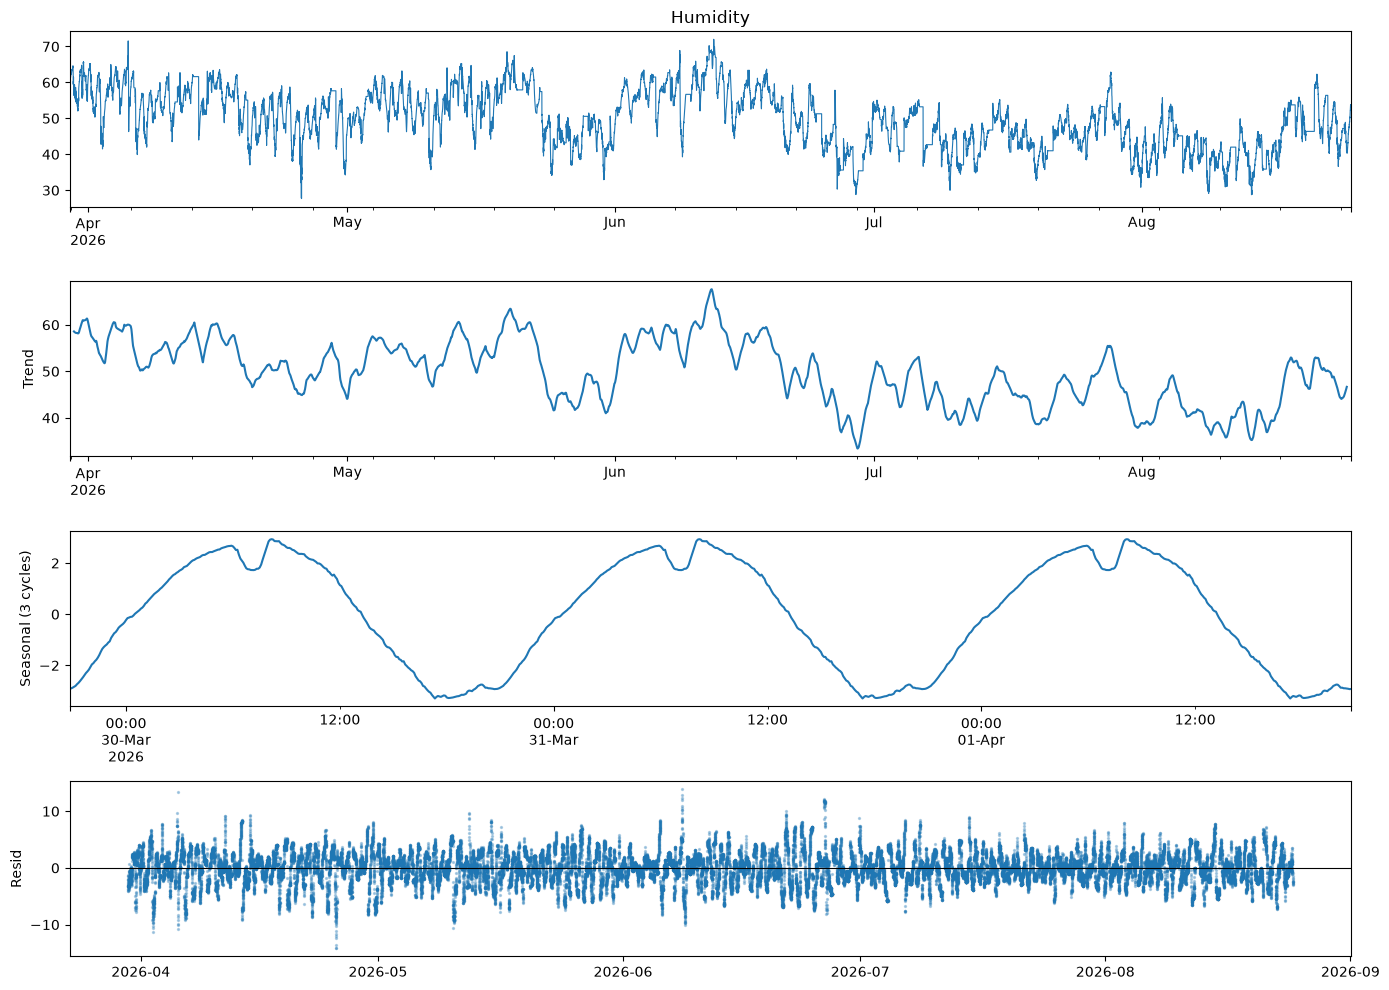

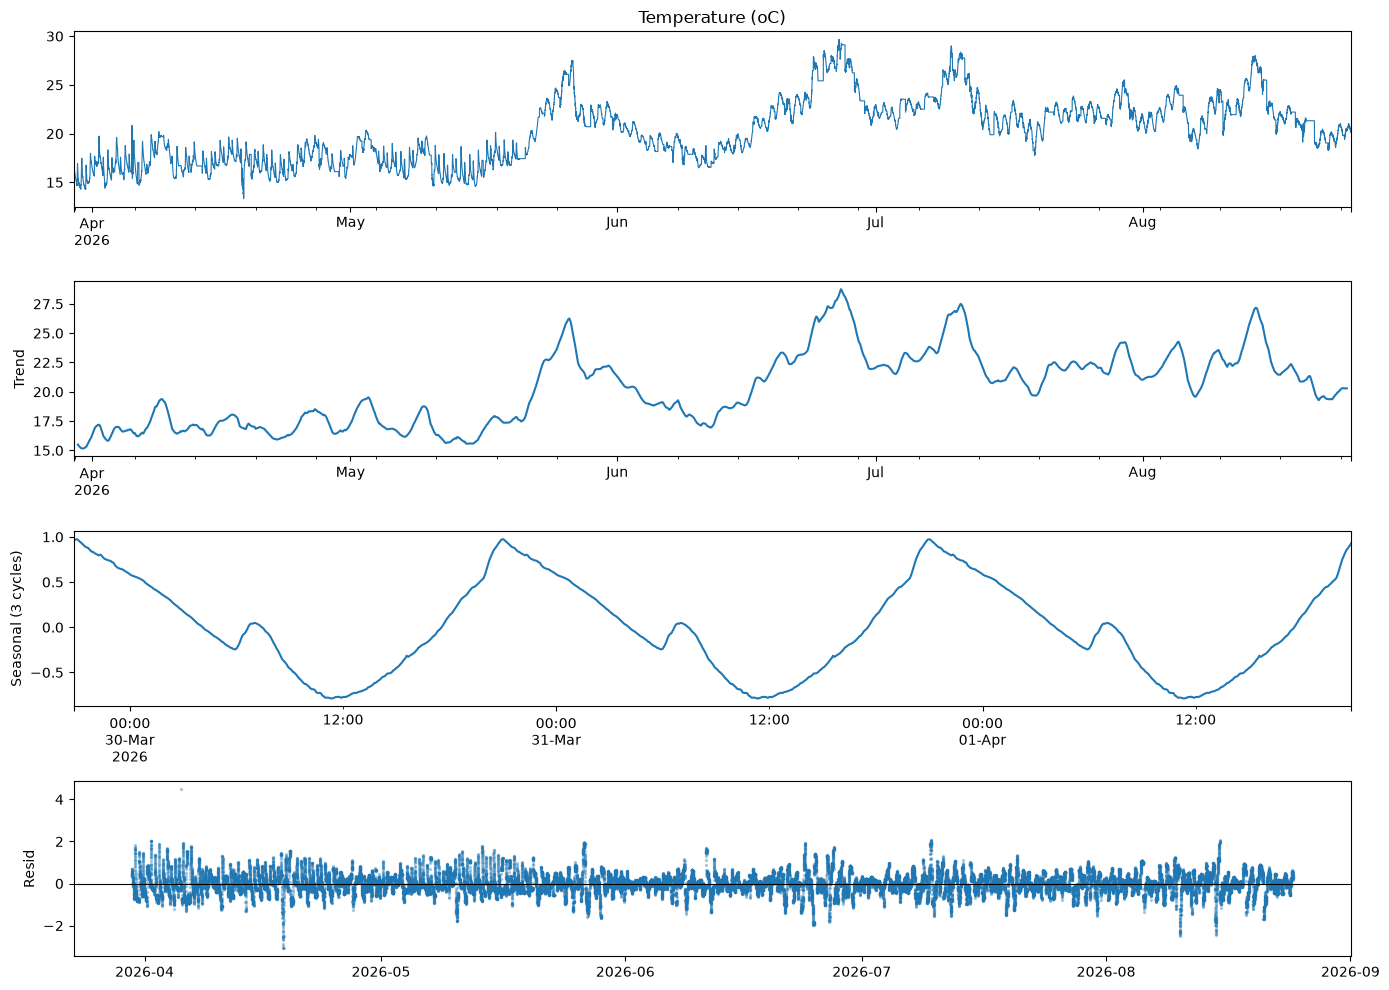

In [6]:
season_decomp(df=train_df,resample_size="5min")


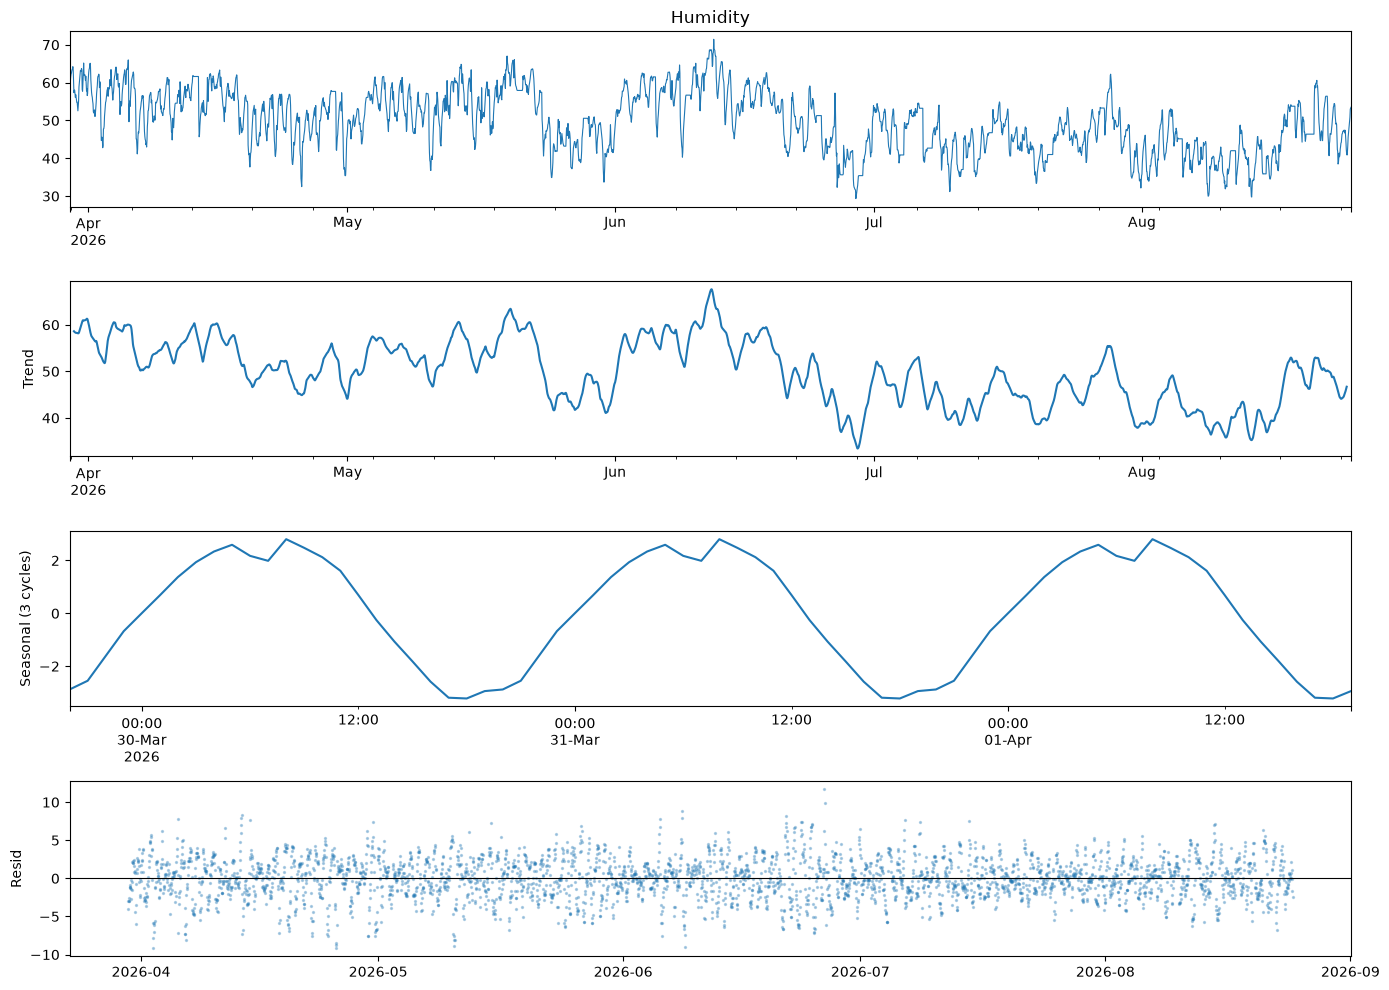

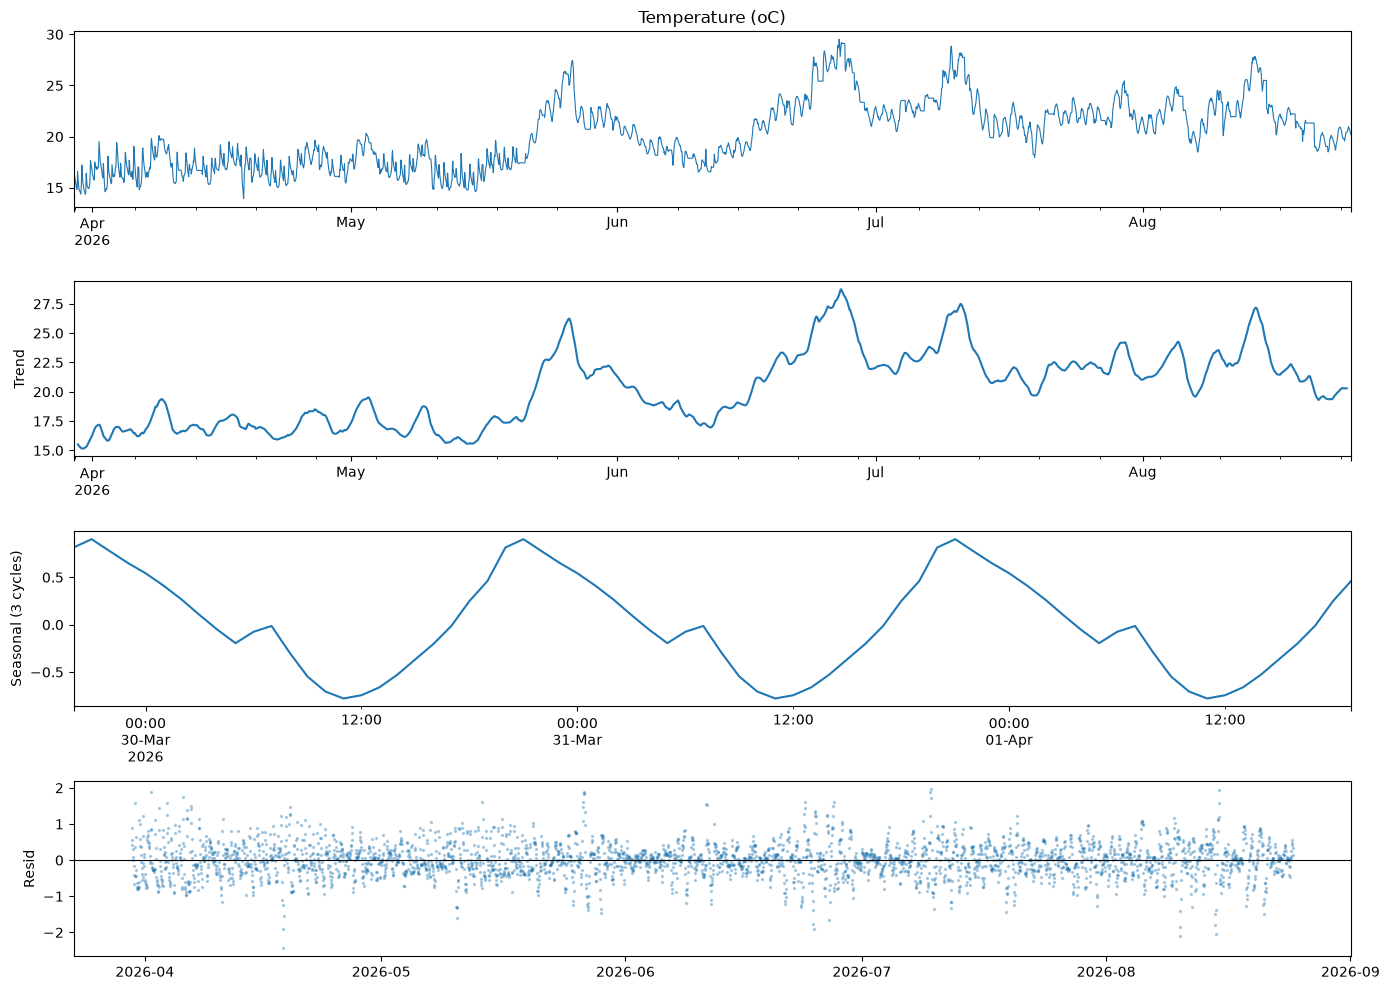

In [7]:
season_decomp(df=train_df,resample_size="1h")

### Modelling

* Naive and seasonal naive baselines
* Classical statistical model (ARIMA / SARIMA)
* Machine learning models (lag and rolling features)
* Model comparison and evaluation

### Results